In [1]:
import os, glob
import numpy as np
import pandas as pd
import SimpleITK as sitk
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

DATA = r"E:\luna16"
ann = pd.read_csv(os.path.join(DATA, "annotations.csv"))

def window(img, level, width):
    lo = level - width / 2
    hi = level + width / 2
    return (np.clip(img, lo, hi) - lo) / (hi - lo)

patches, masks = [], []

for mhd in sorted(glob.glob(os.path.join(DATA, "*.mhd"))):
    uid = os.path.basename(mhd)[:-4]
    nolist = ann[ann["seriesuid"] == uid]
    if len(nolist) == 0:
        continue    # 跳过没结节的 CT

    img = sitk.ReadImage(mhd)
    arr = sitk.GetArrayFromImage(img)
    sp_xy = img.GetSpacing()[0]

    for _, row in nolist.iterrows():
        world = (row["coordX"], row["coordY"], row["coordZ"])
        voxel = img.TransformPhysicalPointToIndex(world)   # (x, y, z)
        cx, cy, cz = voxel[0], voxel[1], voxel[2]
        R = (row["diameter_mm"] / 2) / sp_xy               # 半径（像素）

        for z in (cz - 1, cz, cz + 1):    # 中心附近 3 层
            if z < 0 or z >= arr.shape[0]:
                continue
            r = 32
            x0, y0 = cx - r, cy - r
            if x0 < 0 or y0 < 0 or x0+64 > arr.shape[2] or y0+64 > arr.shape[1]:
                continue   # 靠边缘的跳过
            patch = arr[z, y0:y0+64, x0:x0+64].astype(np.float32)

            yy, xx = np.ogrid[:64, :64]
            mask = ((xx - 32)**2 + (yy - 32)**2) <= R**2    # 圆
            patches.append(patch)
            masks.append(mask.astype(np.float32))

patches = np.stack(patches)
masks   = np.stack(masks)
print("patches:", patches.shape)   # 期望 (12, 64, 64)
print("masks  :", masks.shape)

patches: (12, 64, 64)
masks  : (12, 64, 64)


In [2]:
import torch
from torch.utils.data import DataLoader
from monai.data import Dataset
from monai.transforms import Compose, ScaleIntensityRanged, EnsureChannelFirstd, ToTensord
from monai.networks.nets import UNet
from monai.losses import DiceCELoss
from monai.transforms import RandFlipd, RandRotated

train_transforms = Compose([
    ScaleIntensityRanged(keys=["image"], a_min=-1350, a_max=150, b_min=0.0, b_max=1.0, clip=True),
    EnsureChannelFirstd(keys=["image", "label"], channel_dim="no_channel"),
    RandFlipd(keys=["image", "label"], prob=0.5),        # 加增强
    RandRotated(keys=["image", "label"], range_x=0.2, prob=0.5),
    ToTensord(keys=["image", "label"]),
])

data = [{"image": patches[i], "label": masks[i]} for i in range(len(patches))]
ds = Dataset(data=data, transform=train_transforms)
loader = DataLoader(ds, batch_size=4, shuffle=True)

model = UNet(spatial_dims=2, in_channels=1, out_channels=1,
             channels=(16, 32, 64, 128, 256), strides=(2, 2, 2, 2), num_res_units=2)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = DiceCELoss(sigmoid=True)

for epoch in range(100):
    model.train()
    epoch_loss = 0
    for batch in loader:
        x, y = batch["image"], batch["label"]
        optimizer.zero_grad()
        out = model(x)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch+1:3d}: loss = {epoch_loss/len(loader):.4f}")

D:\Anaconda3\Lib\site-packages\torch\jit\_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


epoch  10: loss = 1.6743
epoch  20: loss = 1.6211
epoch  30: loss = 1.5865
epoch  40: loss = 1.5548
epoch  50: loss = 1.5252
epoch  60: loss = 1.4977
epoch  70: loss = 1.4713
epoch  80: loss = 1.4444
epoch  90: loss = 1.4174
epoch 100: loss = 1.3894


样本0: 预测值 [0.312, 1.000]  前景占比 预测=0.021 真值=0.015


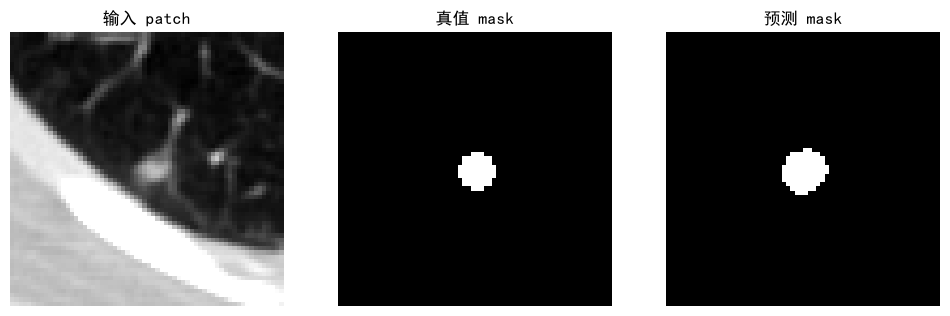

样本3: 预测值 [0.272, 0.997]  前景占比 预测=0.134 真值=0.119


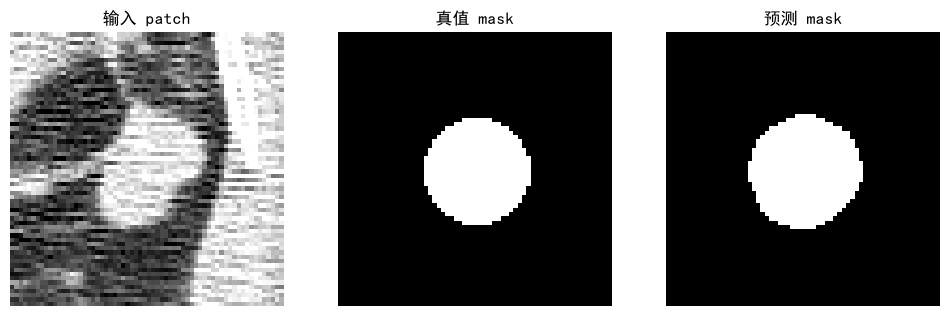

样本6: 预测值 [0.278, 1.000]  前景占比 预测=0.017 真值=0.011


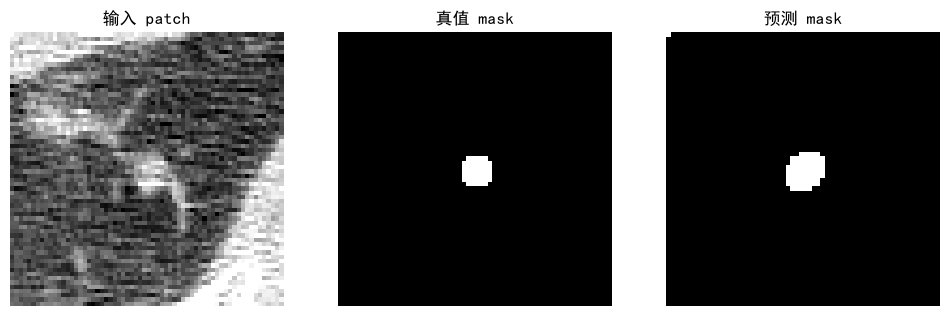

样本9: 预测值 [0.184, 1.000]  前景占比 预测=0.012 真值=0.007


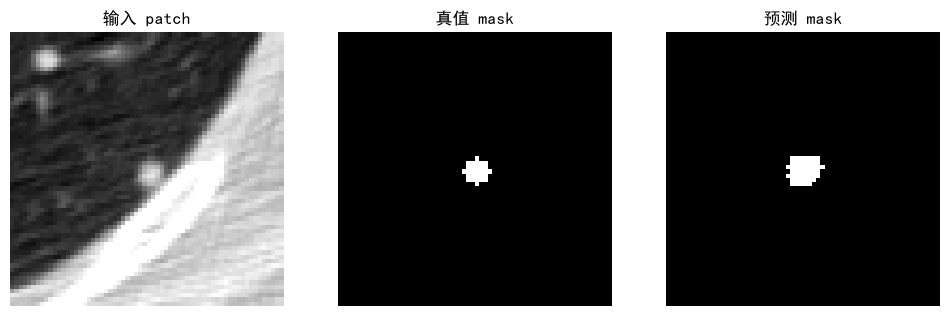

In [3]:
import torch
import numpy as np

def normalize(patch):   # 和训练时的 ScaleIntensityRanged 完全一致
    return np.clip((patch + 1350) / 1500, 0, 1)

model.eval()
with torch.no_grad():
    for idx in [0, 3, 6, 9]:   # 挑 4 个样本看
        p = patches[idx]                                    # (64,64) 原始 HU
        x = torch.tensor(normalize(p)[None, None], dtype=torch.float32)  # (1,1,64,64)
        out = model(x)                                      # logits
        pred = torch.sigmoid(out)[0, 0].numpy()             # 概率 [0,1]
        pred_bin = (pred > 0.5).astype(np.float32)          # 二值化

        print(f"样本{idx}: 预测值 [{pred.min():.3f}, {pred.max():.3f}]  "
              f"前景占比 预测={pred_bin.mean():.3f} 真值={masks[idx].mean():.3f}")

        fig, axes = plt.subplots(1, 3, figsize=(12, 4))
        axes[0].imshow(window(p, -600, 1500), cmap="gray"); axes[0].set_title("输入 patch")
        axes[1].imshow(masks[idx], cmap="gray");         axes[1].set_title("真值 mask")
        axes[2].imshow(pred_bin, cmap="gray");           axes[2].set_title("预测 mask")
        for ax in axes: ax.axis("off")
        plt.show()

In [4]:
import numpy as np
import torch

def dice_score(pred_bin, mask):
    inter = (pred_bin * mask).sum()
    denom = pred_bin.sum() + mask.sum()
    return 2 * inter / denom if denom > 0 else 0.0

model.eval()
dices = []
with torch.no_grad():
    for i in range(len(patches)):
        x = torch.tensor(normalize(patches[i])[None, None], dtype=torch.float32)
        out = model(x)
        pred_bin = (torch.sigmoid(out)[0, 0] > 0.5).float().numpy()
        dices.append(dice_score(pred_bin, masks[i]))

print("每个样本 Dice:", [round(float(d), 3) for d in dices])
print("平均 Dice:", round(float(np.mean(dices)), 3))


每个样本 Dice: [0.83, 0.836, 0.824, 0.944, 0.943, 0.944, 0.783, 0.789, 0.783, 0.744, 0.744, 0.734]
平均 Dice: 0.825
